# The Iterative Revolution: Solving $A \mathbf{x} = \mathbf{b}$
### Steepest Descent, Minimal Residual (MRA), Conjugate Gradients (CG), and Gauss-Seidel / Jacobi

## Problem Definition
Given the $2 \times 2$ linear system:
$$A \mathbf{x} = \mathbf{b}$$

where:
$$A = \begin{bmatrix} 2 & 1 \\ 1 & 3 \end{bmatrix}, \quad \mathbf{b} = \begin{bmatrix} 1 \\ 2 \end{bmatrix}, \quad \mathbf{x} = \begin{bmatrix} x_1 \\ x_2 \end{bmatrix}$$

---

### 1. Matrix Properties
1. **Symmetry:** $A^T = \begin{bmatrix} 2 & 1 \\ 1 & 3 \end{bmatrix} = A$ (Symmetric matrix).
2. **Determinant & Invertibility:** $\det(A) = (2)(3) - (1)(1) = 6 - 1 = 5 \ne 0$ (Non-singular, unique solution exists).
3. **Positive Definiteness:**
   - Trace: $\text{tr}(A) = 2 + 3 = 5 > 0$
   - Determinant: $\det(A) = 5 > 0$
   - Eigenvalues: $\det(A - \lambda I) = \lambda^2 - 5\lambda + 5 = 0 \implies \lambda = \frac{5 \pm \sqrt{5}}{2} \approx 3.618034, \; 1.381966 > 0$.
   Both eigenvalues are strictly positive $\implies A$ is **Symmetric Positive Definite (SPD)**.
4. **Diagonal Dominance:**
   - Row 1: $|A_{11}| = 2 > |A_{12}| = 1$
   - Row 2: $|A_{22}| = 3 > |A_{21}| = 1$
   $A$ is **strictly diagonally dominant**, which mathematically guarantees convergence for matrix-splitting methods (Jacobi and Gauss-Seidel).
5. **Condition Number:** $\kappa(A) = \frac{\lambda_{\max}}{\lambda_{\min}} = \frac{3.618034}{1.381966} \approx 2.6180$ (Well-conditioned system).

### 2. Analytical Benchmark Solution ($A^{-1} \mathbf{b}$)
For a $2 \times 2$ matrix, the exact inverse is:
$$A^{-1} = \frac{1}{\det(A)} \begin{bmatrix} 3 & -1 \\ -1 & 2 \end{bmatrix} = \frac{1}{5} \begin{bmatrix} 3 & -1 \\ -1 & 2 \end{bmatrix} = \begin{bmatrix} 0.6 & -0.2 \\ -0.2 & 0.4 \end{bmatrix}$$

Computing the true solution vector $\mathbf{x}^*$:
$$\mathbf{x}^* = A^{-1} \mathbf{b} = \frac{1}{5} \begin{bmatrix} 3 & -1 \\ -1 & 2 \end{bmatrix} \begin{bmatrix} 1 \\ 2 \end{bmatrix} = \frac{1}{5} \begin{bmatrix} 3(1) - 1(2) \\ -1(1) + 2(2) \end{bmatrix} = \frac{1}{5} \begin{bmatrix} 1 \\ 3 \end{bmatrix} = \begin{bmatrix} 0.2 \\ 0.6 \end{bmatrix}$$


---
## Theoretical Foundations: The Four Core Iterative Methods

### 1. The Steepest Descent Algorithm (Lecture Slide 25)
* **Objective:** Minimize the quadratic energy functional bowl:
  $$\phi(\mathbf{x}) = \frac{1}{2} \mathbf{x}^T A \mathbf{x} - \mathbf{b}^T \mathbf{x}$$
* **Gradient & Direction:** The negative gradient is the residual $\mathbf{r}_k = -\nabla \phi(\mathbf{x}_k) = \mathbf{b} - A \mathbf{x}_k$. We choose search direction $\mathbf{p}_k = \mathbf{r}_k$.
* **Step Length Derivation:** Minimize $\phi(\mathbf{x}_k + d_k \mathbf{r}_k)$ with respect to $d_k$:
  $$\frac{d}{d(d_k)} \phi(\mathbf{x}_k + d_k \mathbf{r}_k) = 0 \implies d_k = \frac{\mathbf{r}_k^T \mathbf{r}_k}{\mathbf{r}_k^T A \mathbf{r}_k}$$
* **Orthogonality Property:** Consecutive search directions are orthogonal: $\mathbf{r}_{k+1}^T \mathbf{r}_k = 0$. In stiff systems (high $\kappa$), this creates inefficient $90^\circ$ zig-zagging.

---

### 2. The Minimal Residual Algorithm (MRA) (Lecture Slide 27)
* **Objective:** Directly minimize the **Euclidean residual 2-norm** $\|\mathbf{r}_{k+1}\|^2 = \|\mathbf{b} - A \mathbf{x}_{k+1}\|^2$ at each step.
* **Recurrence:** $\mathbf{x}_{k+1} = \mathbf{x}_k + d_k \mathbf{r}_k \implies \mathbf{r}_{k+1} = \mathbf{r}_k - d_k A \mathbf{r}_k$.
* **Step Length Derivation:**
  $$\frac{\partial \|\mathbf{r}_{k+1}\|^2}{\partial d_k} = \frac{\partial}{\partial d_k} \left[ \mathbf{r}_k^T \mathbf{r}_k - 2 d_k \mathbf{r}_k^T A \mathbf{r}_k + d_k^2 (A \mathbf{r}_k)^T (A \mathbf{r}_k) \right] = 0$$
  $$\implies d_k = \frac{\mathbf{r}_k^T A \mathbf{r}_k}{(A \mathbf{r}_k)^T (A \mathbf{r}_k)} = \frac{\mathbf{r}_k^T A \mathbf{r}_k}{\mathbf{r}_k^T A^T A \mathbf{r}_k}$$
* **Advantage:** Functions reliably on symmetric indefinite matrices where energy minimization fails.

---

### 3. The Conjugate Gradient (CG) Algorithm (Lecture Slides 28–30)
Published by Hestenes & Stiefel (1952), CG is the definitive solver for symmetric positive definite systems.

* **Core Principle ($A$-Conjugacy):** Search directions $\mathbf{p}_0, \mathbf{p}_1, \dots$ are constructed to be mutually **$A$-orthogonal**:
  $$\mathbf{p}_i^T A \mathbf{p}_j = 0 \quad \text{for all } i \ne j$$
  Minimizing error along $\mathbf{p}_k$ **never disturbs** the minimization already achieved along earlier directions $\mathbf{p}_0, \dots, \mathbf{p}_{k-1}$.
* **Update Rules (Slide 29):**
  $$\alpha_k = \frac{\mathbf{r}_k^T \mathbf{r}_k}{\mathbf{p}_k^T A \mathbf{p}_k}, \quad \mathbf{x}_{k+1} = \mathbf{x}_k + \alpha_k \mathbf{p}_k, \quad \mathbf{r}_{k+1} = \mathbf{r}_k - \alpha_k A \mathbf{p}_k$$
  $$\beta_k = \frac{\mathbf{r}_{k+1}^T \mathbf{r}_{k+1}}{\mathbf{r}_k^T \mathbf{r}_k}, \quad \mathbf{p}_{k+1} = \mathbf{r}_{k+1} + \beta_k \mathbf{p}_k$$
* **Finite $N$-Step Termination (Slide 30):** For any $N \times N$ SPD matrix in exact arithmetic, CG reaches the **exact mathematical solution in at most $N$ iterations**. For our $2 \times 2$ system, CG terminates at $\mathbf{x}^*$ in **exactly 2 iterations**!

---

### 4. Matrix Splitting: Gauss-Jacobi & Gauss-Seidel (Lecture Slide 33)
Decompose $A$ into an "easy" diagonal/triangular part and an "off-diagonal coupling" part: $A = D + E$.

1. **Gauss-Jacobi:** $D \mathbf{x}_{k+1} = \mathbf{b} - E \mathbf{x}_k$. Component-wise:
   $$x_{1}^{(k+1)} = \frac{1 - x_2^{(k)}}{2}, \quad x_{2}^{(k+1)} = \frac{2 - x_1^{(k)}}{3}$$
   Iteration matrix $T_J = -D^{-1}E = \begin{bmatrix} 0 & -1/2 \\ -1/3 & 0 \end{bmatrix}$, spectral radius $\rho(T_J) = \frac{1}{\sqrt{6}} \approx 0.4082$.

2. **Gauss-Seidel:** Immediately uses updated components in the same sweep:
   $$x_{1}^{(k+1)} = \frac{1 - x_2^{(k)}}{2}, \quad x_{2}^{(k+1)} = \frac{2 - x_1^{(k+1)}}{3}$$
   Iteration matrix $T_{GS} = (D - L)^{-1} U$, with spectral radius:
   $$\rho(T_{GS}) = \frac{1}{6} = (\rho(T_J))^2 \approx 0.1667$$
   **Gauss-Seidel converges twice as fast as Gauss-Jacobi!**

---
## Step-by-Step Hand Calculations (Every Intermediate Step Worked Out)

Starting guess for all algorithms:
$$\mathbf{x}_0 = \begin{bmatrix} 0 \\ 0 \end{bmatrix}, \quad \mathbf{b} = \begin{bmatrix} 1 \\ 2 \end{bmatrix}, \quad A = \begin{bmatrix} 2 & 1 \\ 1 & 3 \end{bmatrix}$$

Initial residual:
$$\mathbf{r}_0 = \mathbf{b} - A \mathbf{x}_0 = \begin{bmatrix} 1 \\ 2 \end{bmatrix} - \begin{bmatrix} 2 & 1 \\ 1 & 3 \end{bmatrix}\begin{bmatrix} 0 \\ 0 \end{bmatrix} = \begin{bmatrix} 1 \\ 2 \end{bmatrix} - \begin{bmatrix} 0 \\ 0 \end{bmatrix} = \begin{bmatrix} 1 \\ 2 \end{bmatrix}$$
Initial residual norm:
$$\|\mathbf{r}_0\|_2 = \sqrt{1^2 + 2^2} = \sqrt{1 + 4} = \sqrt{5} \approx 2.236068$$

---

### Part A: Steepest Descent (SD)

#### Iteration 0 ($k=0$):
1. **Compute search direction dot product:**
   $$\mathbf{r}_0^T \mathbf{r}_0 = 1^2 + 2^2 = 1 + 4 = 5$$
2. **Compute matrix-vector multiplication $A \mathbf{r}_0$:**
   $$A \mathbf{r}_0 = \begin{bmatrix} 2 & 1 \\ 1 & 3 \end{bmatrix}\begin{bmatrix} 1 \\ 2 \end{bmatrix} = \begin{bmatrix} 2(1) + 1(2) \\ 1(1) + 3(2) \end{bmatrix} = \begin{bmatrix} 2 + 2 \\ 1 + 6 \end{bmatrix} = \begin{bmatrix} 4 \\ 7 \end{bmatrix}$$
3. **Compute denominator $\mathbf{r}_0^T A \mathbf{r}_0$:**
   $$\mathbf{r}_0^T A \mathbf{r}_0 = \begin{bmatrix} 1 & 2 \end{bmatrix}\begin{bmatrix} 4 \\ 7 \end{bmatrix} = 1(4) + 2(7) = 4 + 14 = 18$$
4. **Compute step length $d_0$:**
   $$d_0 = \frac{\mathbf{r}_0^T \mathbf{r}_0}{\mathbf{r}_0^T A \mathbf{r}_0} = \frac{5}{18} \approx 0.277778$$
5. **Update solution estimate $\mathbf{x}_1$:**
   $$\mathbf{x}_1 = \mathbf{x}_0 + d_0 \mathbf{r}_0 = \begin{bmatrix} 0 \\ 0 \end{bmatrix} + \frac{5}{18}\begin{bmatrix} 1 \\ 2 \end{bmatrix} = \begin{bmatrix} 5/18 \\ 10/18 \end{bmatrix} = \begin{bmatrix} 5/18 \\ 5/9 \end{bmatrix} \approx \begin{bmatrix} 0.277778 \\ 0.555556 \end{bmatrix}$$
6. **Compute new residual $\mathbf{r}_1$:**
   $$A \mathbf{x}_1 = \begin{bmatrix} 2 & 1 \\ 1 & 3 \end{bmatrix}\begin{bmatrix} 5/18 \\ 10/18 \end{bmatrix} = \begin{bmatrix} 2(5/18) + 1(10/18) \\ 1(5/18) + 3(10/18) \end{bmatrix} = \begin{bmatrix} 10/18 + 10/18 \\ 5/18 + 30/18 \end{bmatrix} = \begin{bmatrix} 20/18 \\ 35/18 \end{bmatrix}$$
   $$\mathbf{r}_1 = \mathbf{b} - A \mathbf{x}_1 = \begin{bmatrix} 1 \\ 2 \end{bmatrix} - \begin{bmatrix} 20/18 \\ 35/18 \end{bmatrix} = \begin{bmatrix} 18/18 - 20/18 \\ 36/18 - 35/18 \end{bmatrix} = \begin{bmatrix} -2/18 \\ 1/18 \end{bmatrix} = \begin{bmatrix} -1/9 \\ 1/18 \end{bmatrix} \approx \begin{bmatrix} -0.111111 \\ 0.055556 \end{bmatrix}$$
7. **Verify gradient orthogonality:**
   $$\mathbf{r}_1^T \mathbf{r}_0 = \left(-\frac{1}{9}\right)(1) + \left(\frac{1}{18}\right)(2) = -\frac{1}{9} + \frac{1}{9} = 0 \quad (\text{Orthogonal!})$$

#### Iteration 1 ($k=1$):
1. **Compute dot product $\mathbf{r}_1^T \mathbf{r}_1$:**
   $$\mathbf{r}_1^T \mathbf{r}_1 = \left(-\frac{1}{9}\right)^2 + \left(\frac{1}{18}\right)^2 = \frac{1}{81} + \frac{1}{324} = \frac{4}{324} + \frac{1}{324} = \frac{5}{324} \approx 0.015432$$
2. **Compute $A \mathbf{r}_1$:**
   $$A \mathbf{r}_1 = \begin{bmatrix} 2 & 1 \\ 1 & 3 \end{bmatrix}\begin{bmatrix} -2/18 \\ 1/18 \end{bmatrix} = \begin{bmatrix} 2(-2/18) + 1(1/18) \\ 1(-2/18) + 3(1/18) \end{bmatrix} = \begin{bmatrix} -4/18 + 1/18 \\ -2/18 + 3/18 \end{bmatrix} = \begin{bmatrix} -3/18 \\ 1/18 \end{bmatrix} = \begin{bmatrix} -1/6 \\ 1/18 \end{bmatrix}$$
3. **Compute $\mathbf{r}_1^T A \mathbf{r}_1$:**
   $$\mathbf{r}_1^T A \mathbf{r}_1 = \begin{bmatrix} -2/18 & 1/18 \end{bmatrix}\begin{bmatrix} -3/18 \\ 1/18 \end{bmatrix} = \frac{(-2)(-3) + (1)(1)}{18^2} = \frac{6 + 1}{324} = \frac{7}{324}$$
4. **Compute step length $d_1$:**
   $$d_1 = \frac{\mathbf{r}_1^T \mathbf{r}_1}{\mathbf{r}_1^T A \mathbf{r}_1} = \frac{5/324}{7/324} = \frac{5}{7} \approx 0.714286$$
5. **Update solution estimate $\mathbf{x}_2$:**
   $$\mathbf{x}_2 = \mathbf{x}_1 + d_1 \mathbf{r}_1 = \begin{bmatrix} 5/18 \\ 10/18 \end{bmatrix} + \frac{5}{7}\begin{bmatrix} -2/18 \\ 1/18 \end{bmatrix} = \begin{bmatrix} \frac{5}{18} - \frac{10}{126} \\ \frac{10}{18} + \frac{5}{126} \end{bmatrix} = \begin{bmatrix} \frac{35 - 10}{126} \\ \frac{70 + 5}{126} \end{bmatrix} = \begin{bmatrix} 25/126 \\ 75/126 \end{bmatrix} = \begin{bmatrix} 25/126 \\ 25/42 \end{bmatrix} \approx \begin{bmatrix} 0.198413 \\ 0.595238 \end{bmatrix}$$
6. **Compute residual $\mathbf{r}_2$:**
   $$A \mathbf{x}_2 = \begin{bmatrix} 2 & 1 \\ 1 & 3 \end{bmatrix}\begin{bmatrix} 25/126 \\ 75/126 \end{bmatrix} = \begin{bmatrix} \frac{2(25) + 1(75)}{126} \\ \frac{1(25) + 3(75)}{126} \end{bmatrix} = \begin{bmatrix} \frac{50 + 75}{126} \\ \frac{25 + 225}{126} \end{bmatrix} = \begin{bmatrix} 125/126 \\ 250/126 \end{bmatrix}$$
   $$\mathbf{r}_2 = \begin{bmatrix} 1 \\ 2 \end{bmatrix} - \begin{bmatrix} 125/126 \\ 250/126 \end{bmatrix} = \begin{bmatrix} 126/126 - 125/126 \\ 252/126 - 250/126 \end{bmatrix} = \begin{bmatrix} 1/126 \\ 2/126 \end{bmatrix} = \frac{1}{126}\begin{bmatrix} 1 \\ 2 \end{bmatrix} = \frac{1}{126}\mathbf{r}_0 \approx \begin{bmatrix} 0.007937 \\ 0.015873 \end{bmatrix}$$

---

### Part B: Minimal Residual Algorithm (MRA)

#### Iteration 0 ($k=0$):
1. **Compute $A \mathbf{r}_0$:**
   $$A \mathbf{r}_0 = \begin{bmatrix} 2 & 1 \\ 1 & 3 \end{bmatrix}\begin{bmatrix} 1 \\ 2 \end{bmatrix} = \begin{bmatrix} 4 \\ 7 \end{bmatrix}$$
2. **Compute numerator $\mathbf{r}_0^T A \mathbf{r}_0$ and denominator $(A \mathbf{r}_0)^T (A \mathbf{r}_0)$:**
   $$\text{Numerator: } \mathbf{r}_0^T A \mathbf{r}_0 = 1(4) + 2(7) = 4 + 14 = 18$$
   $$\text{Denominator: } (A \mathbf{r}_0)^T (A \mathbf{r}_0) = 4^2 + 7^2 = 16 + 49 = 65$$
3. **Compute step length $d_0$:**
   $$d_0 = \frac{\mathbf{r}_0^T A \mathbf{r}_0}{(A \mathbf{r}_0)^T (A \mathbf{r}_0)} = \frac{18}{65} \approx 0.276923$$
4. **Update solution estimate $\mathbf{x}_1$:**
   $$\mathbf{x}_1 = \mathbf{x}_0 + d_0 \mathbf{r}_0 = \begin{bmatrix} 0 \\ 0 \end{bmatrix} + \frac{18}{65}\begin{bmatrix} 1 \\ 2 \end{bmatrix} = \begin{bmatrix} 18/65 \\ 36/65 \end{bmatrix} \approx \begin{bmatrix} 0.276923 \\ 0.553846 \end{bmatrix}$$
5. **Compute updated residual $\mathbf{r}_1$:**
   $$A \mathbf{x}_1 = \begin{bmatrix} 2 & 1 \\ 1 & 3 \end{bmatrix}\begin{bmatrix} 18/65 \\ 36/65 \end{bmatrix} = \begin{bmatrix} \frac{2(18) + 1(36)}{65} \\ \frac{1(18) + 3(36)}{65} \end{bmatrix} = \begin{bmatrix} \frac{36 + 36}{65} \\ \frac{18 + 108}{65} \end{bmatrix} = \begin{bmatrix} 72/65 \\ 126/65 \end{bmatrix}$$
   $$\mathbf{r}_1 = \mathbf{b} - A \mathbf{x}_1 = \begin{bmatrix} 1 \\ 2 \end{bmatrix} - \begin{bmatrix} 72/65 \\ 126/65 \end{bmatrix} = \begin{bmatrix} 65/65 - 72/65 \\ 130/65 - 126/65 \end{bmatrix} = \begin{bmatrix} -7/65 \\ 4/65 \end{bmatrix} \approx \begin{bmatrix} -0.107692 \\ 0.061538 \end{bmatrix}$$

#### Iteration 1 ($k=1$):
1. **Compute $A \mathbf{r}_1$:**
   $$A \mathbf{r}_1 = \begin{bmatrix} 2 & 1 \\ 1 & 3 \end{bmatrix}\begin{bmatrix} -7/65 \\ 4/65 \end{bmatrix} = \begin{bmatrix} \frac{2(-7) + 1(4)}{65} \\ \frac{1(-7) + 3(4)}{65} \end{bmatrix} = \begin{bmatrix} \frac{-14 + 4}{65} \\ \frac{-7 + 12}{65} \end{bmatrix} = \begin{bmatrix} -10/65 \\ 5/65 \end{bmatrix} = \begin{bmatrix} -2/13 \\ 1/13 \end{bmatrix}$$
2. **Compute numerator $\mathbf{r}_1^T A \mathbf{r}_1$:**
   $$\mathbf{r}_1^T A \mathbf{r}_1 = \left(-\frac{7}{65}\right)\left(-\frac{10}{65}\right) + \left(\frac{4}{65}\right)\left(\frac{5}{65}\right) = \frac{70 + 20}{65^2} = \frac{90}{4225} = \frac{18}{845}$$
3. **Compute denominator $(A \mathbf{r}_1)^T (A \mathbf{r}_1)$:**
   $$(A \mathbf{r}_1)^T (A \mathbf{r}_1) = \left(-\frac{10}{65}\right)^2 + \left(\frac{5}{65}\right)^2 = \frac{100 + 25}{4225} = \frac{125}{4225} = \frac{25}{845}$$
4. **Compute step length $d_1$:**
   $$d_1 = \frac{18/845}{25/845} = \frac{18}{25} = 0.72$$
5. **Update solution estimate $\mathbf{x}_2$:**
   $$\mathbf{x}_2 = \mathbf{x}_1 + d_1 \mathbf{r}_1 = \begin{bmatrix} 18/65 \\ 36/65 \end{bmatrix} + \frac{18}{25}\begin{bmatrix} -7/65 \\ 4/65 \end{bmatrix} = \begin{bmatrix} \frac{18(25) - 18(7)}{1625} \\ \frac{36(25) + 18(4)}{1625} \end{bmatrix} = \begin{bmatrix} \frac{450 - 126}{1625} \\ \frac{900 + 72}{1625} \end{bmatrix} = \begin{bmatrix} 324/1625 \\ 972/1625 \end{bmatrix} \approx \begin{bmatrix} 0.199385 \\ 0.598154 \end{bmatrix}$$
6. **Compute residual $\mathbf{r}_2$:**
   $$A \mathbf{x}_2 = \begin{bmatrix} 2 & 1 \\ 1 & 3 \end{bmatrix}\begin{bmatrix} 324/1625 \\ 972/1625 \end{bmatrix} = \begin{bmatrix} \frac{648 + 972}{1625} \\ \frac{324 + 2916}{1625} \end{bmatrix} = \begin{bmatrix} 1620/1625 \\ 3240/1625 \end{bmatrix}$$
   $$\mathbf{r}_2 = \begin{bmatrix} 1 \\ 2 \end{bmatrix} - \begin{bmatrix} 1620/1625 \\ 3240/1625 \end{bmatrix} = \begin{bmatrix} 1625/1625 - 1620/1625 \\ 3250/1625 - 3240/1625 \end{bmatrix} = \begin{bmatrix} 5/1625 \\ 10/1625 \end{bmatrix} = \begin{bmatrix} 1/325 \\ 2/325 \end{bmatrix} \approx \begin{bmatrix} 0.003077 \\ 0.006154 \end{bmatrix}$$

---

### Part C: Conjugate Gradient Algorithm (CG)

#### Iteration 0 ($k=0$):
1. **Initialize search direction:** $\mathbf{p}_0 = \mathbf{r}_0 = \begin{bmatrix} 1 \\ 2 \end{bmatrix}$, $\quad \mathbf{r}_0^T \mathbf{r}_0 = 1^2 + 2^2 = 5$
2. **Compute $A \mathbf{p}_0$ and $\mathbf{p}_0^T A \mathbf{p}_0$:**
   $$A \mathbf{p}_0 = \begin{bmatrix} 2 & 1 \\ 1 & 3 \end{bmatrix}\begin{bmatrix} 1 \\ 2 \end{bmatrix} = \begin{bmatrix} 4 \\ 7 \end{bmatrix}, \quad \mathbf{p}_0^T A \mathbf{p}_0 = 1(4) + 2(7) = 18$$
3. **Compute step length $\alpha_0$:**
   $$\alpha_0 = \frac{\mathbf{r}_0^T \mathbf{r}_0}{\mathbf{p}_0^T A \mathbf{p}_0} = \frac{5}{18} \approx 0.277778$$
4. **Update solution estimate $\mathbf{x}_1$:**
   $$\mathbf{x}_1 = \mathbf{x}_0 + \alpha_0 \mathbf{p}_0 = \begin{bmatrix} 0 \\ 0 \end{bmatrix} + \frac{5}{18}\begin{bmatrix} 1 \\ 2 \end{bmatrix} = \begin{bmatrix} 5/18 \\ 10/18 \end{bmatrix} = \begin{bmatrix} 5/18 \\ 5/9 \end{bmatrix} \approx \begin{bmatrix} 0.277778 \\ 0.555556 \end{bmatrix}$$
5. **Update residual $\mathbf{r}_1$:**
   $$\mathbf{r}_1 = \mathbf{r}_0 - \alpha_0 A \mathbf{p}_0 = \begin{bmatrix} 1 \\ 2 \end{bmatrix} - \frac{5}{18}\begin{bmatrix} 4 \\ 7 \end{bmatrix} = \begin{bmatrix} 18/18 - 20/18 \\ 36/18 - 35/18 \end{bmatrix} = \begin{bmatrix} -2/18 \\ 1/18 \end{bmatrix} = \begin{bmatrix} -1/9 \\ 1/18 \end{bmatrix}$$
   $$\mathbf{r}_1^T \mathbf{r}_1 = \left(-\frac{1}{9}\right)^2 + \left(\frac{1}{18}\right)^2 = \frac{4}{324} + \frac{1}{324} = \frac{5}{324}$$
6. **Compute Gram-Schmidt orthogonalization scalar $\beta_0$:**
   $$\beta_0 = \frac{\mathbf{r}_1^T \mathbf{r}_1}{\mathbf{r}_0^T \mathbf{r}_0} = \frac{5/324}{5} = \frac{1}{324}$$
7. **Construct next $A$-conjugate search direction $\mathbf{p}_1$:**
   $$\mathbf{p}_1 = \mathbf{r}_1 + \beta_0 \mathbf{p}_0 = \begin{bmatrix} -1/9 \\ 1/18 \end{bmatrix} + \frac{1}{324}\begin{bmatrix} 1 \\ 2 \end{bmatrix} = \begin{bmatrix} -36/324 + 1/324 \\ 18/324 + 2/324 \end{bmatrix} = \begin{bmatrix} -35/324 \\ 20/324 \end{bmatrix} = \begin{bmatrix} -35/324 \\ 5/81 \end{bmatrix}$$
8. **Check $A$-orthogonality:**
   $$A \mathbf{p}_1 = \begin{bmatrix} 2 & 1 \\ 1 & 3 \end{bmatrix}\begin{bmatrix} -35/324 \\ 20/324 \end{bmatrix} = \begin{bmatrix} \frac{2(-35) + 1(20)}{324} \\ \frac{1(-35) + 3(20)}{324} \end{bmatrix} = \begin{bmatrix} \frac{-70 + 20}{324} \\ \frac{-35 + 60}{324} \end{bmatrix} = \begin{bmatrix} -50/324 \\ 25/324 \end{bmatrix}$$
   $$\mathbf{p}_0^T A \mathbf{p}_1 = \begin{bmatrix} 1 & 2 \end{bmatrix}\begin{bmatrix} -50/324 \\ 25/324 \end{bmatrix} = \frac{1(-50) + 2(25)}{324} = \frac{-50 + 50}{324} = 0 \quad (\text{Exact!})$$

#### Iteration 1 ($k=1$):
1. **Compute denominator $\mathbf{p}_1^T A \mathbf{p}_1$:**
   $$\mathbf{p}_1^T A \mathbf{p}_1 = \left(-\frac{35}{324}\right)\left(-\frac{50}{324}\right) + \left(\frac{20}{324}\right)\left(\frac{25}{324}\right) = \frac{1750 + 500}{324^2} = \frac{2250}{104976} = \frac{125}{5832}$$
2. **Compute step length $\alpha_1$:**
   $$\alpha_1 = \frac{\mathbf{r}_1^T \mathbf{r}_1}{\mathbf{p}_1^T A \mathbf{p}_1} = \frac{5/324}{125/5832} = \frac{5}{324} \times \frac{5832}{125} = \frac{1}{1} \times \frac{18}{25} = \frac{18}{25} = 0.72$$
3. **Update solution estimate $\mathbf{x}_2$:**
   $$\mathbf{x}_2 = \mathbf{x}_1 + \alpha_1 \mathbf{p}_1 = \begin{bmatrix} 5/18 \\ 5/9 \end{bmatrix} + \frac{18}{25}\begin{bmatrix} -35/324 \\ 20/324 \end{bmatrix} = \begin{bmatrix} \frac{5}{18} - \frac{18 \times 35}{25 \times 324} \\ \frac{5}{9} + \frac{18 \times 20}{25 \times 324} \end{bmatrix} = \begin{bmatrix} \frac{5}{18} - \frac{7}{90} \\ \frac{5}{9} + \frac{2}{45} \end{bmatrix} = \begin{bmatrix} \frac{25 - 7}{90} \\ \frac{25 + 2}{45} \end{bmatrix} = \begin{bmatrix} 18/90 \\ 27/45 \end{bmatrix} = \begin{bmatrix} 1/5 \\ 3/5 \end{bmatrix} = \begin{bmatrix} 0.2 \\ 0.6 \end{bmatrix} = \mathbf{x}^*$$
4. **Update residual $\mathbf{r}_2$:**
   $$\mathbf{r}_2 = \mathbf{r}_1 - \alpha_1 A \mathbf{p}_1 = \begin{bmatrix} -1/9 \\ 1/18 \end{bmatrix} - \frac{18}{25}\begin{bmatrix} -50/324 \\ 25/324 \end{bmatrix} = \begin{bmatrix} -1/9 - (-1/9) \\ 1/18 - 1/18 \end{bmatrix} = \begin{bmatrix} 0 \\ 0 \end{bmatrix}$$
   **The exact analytical solution is reached in exactly $N = 2$ steps with ZERO residual!**

---

### Part D: Matrix Splitting (Gauss-Seidel & Gauss-Jacobi)

The linear system in scalar equations:
$$\text{Equation 1: } 2x_1 + x_2 = 1 \implies 2x_1 = 1 - x_2 \implies x_1 = \frac{1 - x_2}{2}$$
$$\text{Equation 2: } x_1 + 3x_2 = 2 \implies 3x_2 = 2 - x_1 \implies x_2 = \frac{2 - x_1}{3}$$

Initial state: $\mathbf{x}_0 = \begin{bmatrix} x_1^{(0)} \\ x_2^{(0)} \end{bmatrix} = \begin{bmatrix} 0 \\ 0 \end{bmatrix}$

---

#### 1. Gauss-Seidel Method (Immediate In-Place Substitution)

* **Sweep 1 ($k=1$):**
  1. Solve Equation 1 for $x_1^{(1)}$ using previous $x_2^{(0)} = 0$:
     $$x_1^{(1)} = \frac{1 - x_2^{(0)}}{2} = \frac{1 - 0}{2} = \frac{1}{2} = 0.5$$
  2. Solve Equation 2 for $x_2^{(1)}$ **immediately using the newly updated** $x_1^{(1)} = \frac{1}{2}$:
     $$x_2^{(1)} = \frac{2 - x_1^{(1)}}{3} = \frac{2 - \frac{1}{2}}{3} = \frac{\frac{3}{2}}{3} = \frac{1}{2} = 0.5$$
  3. Solution vector: $\mathbf{x}_1 = \begin{bmatrix} 1/2 \\ 1/2 \end{bmatrix} = \begin{bmatrix} 0.5 \\ 0.5 \end{bmatrix}$
  4. Full residual calculation $\mathbf{r}_1 = \mathbf{b} - A \mathbf{x}_1$:
     $$A \mathbf{x}_1 = \begin{bmatrix} 2 & 1 \\ 1 & 3 \end{bmatrix}\begin{bmatrix} 1/2 \\ 1/2 \end{bmatrix} = \begin{bmatrix} 2(1/2) + 1(1/2) \\ 1(1/2) + 3(1/2) \end{bmatrix} = \begin{bmatrix} 1 + 1/2 \\ 1/2 + 3/2 \end{bmatrix} = \begin{bmatrix} 3/2 \\ 2 \end{bmatrix}$$
     $$\mathbf{r}_1 = \begin{bmatrix} 1 \\ 2 \end{bmatrix} - \begin{bmatrix} 3/2 \\ 2 \end{bmatrix} = \begin{bmatrix} 1 - 3/2 \\ 2 - 2 \end{bmatrix} = \begin{bmatrix} -1/2 \\ 0 \end{bmatrix}$$
  5. Residual norm: $\|\mathbf{r}_1\| = \sqrt{(-1/2)^2 + 0^2} = \frac{1}{2} = 0.5$

* **Sweep 2 ($k=2$):**
  1. Solve Equation 1 for $x_1^{(2)}$ using $x_2^{(1)} = \frac{1}{2}$:
     $$x_1^{(2)} = \frac{1 - x_2^{(1)}}{2} = \frac{1 - \frac{1}{2}}{2} = \frac{\frac{1}{2}}{2} = \frac{1}{4} = 0.25$$
  2. Solve Equation 2 for $x_2^{(2)}$ **immediately using the newly updated** $x_1^{(2)} = \frac{1}{4}$:
     $$x_2^{(2)} = \frac{2 - x_1^{(2)}}{3} = \frac{2 - \frac{1}{4}}{3} = \frac{\frac{7}{4}}{3} = \frac{7}{12} \approx 0.583333$$
  3. Solution vector: $\mathbf{x}_2 = \begin{bmatrix} 1/4 \\ 7/12 \end{bmatrix} \approx \begin{bmatrix} 0.25 \\ 0.583333 \end{bmatrix}$
  4. Full residual calculation $\mathbf{r}_2 = \mathbf{b} - A \mathbf{x}_2$:
     $$A \mathbf{x}_2 = \begin{bmatrix} 2 & 1 \\ 1 & 3 \end{bmatrix}\begin{bmatrix} 1/4 \\ 7/12 \end{bmatrix} = \begin{bmatrix} 2(1/4) + 1(7/12) \\ 1(1/4) + 3(7/12) \end{bmatrix} = \begin{bmatrix} 6/12 + 7/12 \\ 3/12 + 21/12 \end{bmatrix} = \begin{bmatrix} 13/12 \\ 24/12 \end{bmatrix} = \begin{bmatrix} 13/12 \\ 2 \end{bmatrix}$$
     $$\mathbf{r}_2 = \begin{bmatrix} 1 \\ 2 \end{bmatrix} - \begin{bmatrix} 13/12 \\ 2 \end{bmatrix} = \begin{bmatrix} 12/12 - 13/12 \\ 2 - 2 \end{bmatrix} = \begin{bmatrix} -1/12 \\ 0 \end{bmatrix}$$
  5. Residual norm: $\|\mathbf{r}_2\| = \frac{1}{12} \approx 0.083333$  
     *(Notice: $\frac{1}{12} = \frac{1}{6} \times \frac{1}{2}$, contracted by exactly $\frac{1}{6}$!)*

* **Sweep 3 ($k=3$):**
  1. Solve Equation 1 for $x_1^{(3)}$ using $x_2^{(2)} = \frac{7}{12}$:
     $$x_1^{(3)} = \frac{1 - x_2^{(2)}}{2} = \frac{1 - \frac{7}{12}}{2} = \frac{\frac{5}{12}}{2} = \frac{5}{24} \approx 0.208333$$
  2. Solve Equation 2 for $x_2^{(3)}$ **immediately using the newly updated** $x_1^{(3)} = \frac{5}{24}$:
     $$x_2^{(3)} = \frac{2 - x_1^{(3)}}{3} = \frac{2 - \frac{5}{24}}{3} = \frac{\frac{43}{24}}{3} = \frac{43}{72} \approx 0.597222$$
  3. Solution vector: $\mathbf{x}_3 = \begin{bmatrix} 5/24 \\ 43/72 \end{bmatrix} \approx \begin{bmatrix} 0.208333 \\ 0.597222 \end{bmatrix}$
  4. Full residual calculation $\mathbf{r}_3 = \mathbf{b} - A \mathbf{x}_3$:
     $$A \mathbf{x}_3 = \begin{bmatrix} 2 & 1 \\ 1 & 3 \end{bmatrix}\begin{bmatrix} 5/24 \\ 43/72 \end{bmatrix} = \begin{bmatrix} 2(15/72) + 1(43/72) \\ 1(15/72) + 3(43/72) \end{bmatrix} = \begin{bmatrix} 30/72 + 43/72 \\ 15/72 + 129/72 \end{bmatrix} = \begin{bmatrix} 73/72 \\ 144/72 \end{bmatrix} = \begin{bmatrix} 73/72 \\ 2 \end{bmatrix}$$
     $$\mathbf{r}_3 = \begin{bmatrix} 1 \\ 2 \end{bmatrix} - \begin{bmatrix} 73/72 \\ 2 \end{bmatrix} = \begin{bmatrix} 72/72 - 73/72 \\ 2 - 2 \end{bmatrix} = \begin{bmatrix} -1/72 \\ 0 \end{bmatrix}$$
  5. Residual norm: $\|\mathbf{r}_3\| = \frac{1}{72} \approx 0.013889$  
     *(Notice: $\frac{1}{72} = \frac{1}{6} \times \frac{1}{12}$, contracting by exactly $\frac{1}{6}$ at every single sweep!)*

---

#### 2. Gauss-Jacobi Method (Simultaneous Step Updates)

In Jacobi iteration, components are updated **simultaneously** using only the values from the previous iteration $k$ (never newly computed values from the current sweep):

* **Sweep 1 ($k=1$):**
  $$x_1^{(1)} = \frac{1 - x_2^{(0)}}{2} = \frac{1 - 0}{2} = \frac{1}{2} = 0.5$$
  $$x_2^{(1)} = \frac{2 - x_1^{(0)}}{3} = \frac{2 - 0}{3} = \frac{2}{3} \approx 0.666667$$
  $$\mathbf{x}_1 = \begin{bmatrix} 1/2 \\ 2/3 \end{bmatrix}$$
  Residual:
  $$A \mathbf{x}_1 = \begin{bmatrix} 2(1/2) + 1(2/3) \\ 1(1/2) + 3(2/3) \end{bmatrix} = \begin{bmatrix} 1 + 2/3 \\ 1/2 + 2 \end{bmatrix} = \begin{bmatrix} 5/3 \\ 5/2 \end{bmatrix}$$
  $$\mathbf{r}_1 = \begin{bmatrix} 1 \\ 2 \end{bmatrix} - \begin{bmatrix} 5/3 \\ 5/2 \end{bmatrix} = \begin{bmatrix} -2/3 \\ -1/2 \end{bmatrix} \implies \|\mathbf{r}_1\| = \sqrt{\frac{4}{9} + \frac{1}{4}} = \sqrt{\frac{25}{36}} = \frac{5}{6} \approx 0.833333$$

* **Sweep 2 ($k=2$):**
  $$x_1^{(2)} = \frac{1 - x_2^{(1)}}{2} = \frac{1 - \frac{2}{3}}{2} = \frac{\frac{1}{3}}{2} = \frac{1}{6} \approx 0.166667$$
  $$x_2^{(2)} = \frac{2 - x_1^{(1)}}{3} = \frac{2 - \frac{1}{2}}{3} = \frac{\frac{3}{2}}{3} = \frac{1}{2} = 0.5$$
  $$\mathbf{x}_2 = \begin{bmatrix} 1/6 \\ 1/2 \end{bmatrix}$$
  Residual:
  $$A \mathbf{x}_2 = \begin{bmatrix} 2(1/6) + 1(1/2) \\ 1(1/6) + 3(1/2) \end{bmatrix} = \begin{bmatrix} 1/3 + 1/2 \\ 1/6 + 3/2 \end{bmatrix} = \begin{bmatrix} 5/6 \\ 5/3 \end{bmatrix}$$
  $$\mathbf{r}_2 = \begin{bmatrix} 1 \\ 2 \end{bmatrix} - \begin{bmatrix} 5/6 \\ 5/3 \end{bmatrix} = \begin{bmatrix} 1/6 \\ 1/3 \end{bmatrix} \implies \|\mathbf{r}_2\| = \sqrt{\frac{1}{36} + \frac{4}{36}} = \frac{\sqrt{5}}{6} \approx 0.372678$$

* **Sweep 3 ($k=3$):**
  $$x_1^{(3)} = \frac{1 - x_2^{(2)}}{2} = \frac{1 - \frac{1}{2}}{2} = \frac{\frac{1}{2}}{2} = \frac{1}{4} = 0.25$$
  $$x_2^{(3)} = \frac{2 - x_1^{(2)}}{3} = \frac{2 - \frac{1}{6}}{3} = \frac{\frac{11}{6}}{3} = \frac{11}{18} \approx 0.611111$$
  $$\mathbf{x}_3 = \begin{bmatrix} 1/4 \\ 11/18 \end{bmatrix}$$
  Residual:
  $$A \mathbf{x}_3 = \begin{bmatrix} 2(1/4) + 1(11/18) \\ 1(1/4) + 3(11/18) \end{bmatrix} = \begin{bmatrix} 9/18 + 11/18 \\ 9/36 + 66/36 \end{bmatrix} = \begin{bmatrix} 20/18 \\ 75/36 \end{bmatrix} = \begin{bmatrix} 10/9 \\ 25/12 \end{bmatrix}$$
  $$\mathbf{r}_3 = \begin{bmatrix} 1 \\ 2 \end{bmatrix} - \begin{bmatrix} 10/9 \\ 25/12 \end{bmatrix} = \begin{bmatrix} -1/9 \\ -1/12 \end{bmatrix} \implies \|\mathbf{r}_3\| = \sqrt{\frac{1}{81} + \frac{1}{144}} = \sqrt{\frac{16 + 9}{1296}} = \frac{5}{36} \approx 0.138889$$

> **Key Comparison**: In Gauss-Seidel, immediately recycling $x_1^{(k+1)}$ forces the second equation's residual component to exactly zero ($r_2 = 0$) at the end of every sweep. This collapses the 2D cross-axial oscillations seen in Jacobi into a direct geometric contraction of rate $\rho = \frac{1}{6}$, doubling the convergence speed!


In [1]:
import numpy as np

# Problem matrices
A = np.array([[2.0, 1.0], 
              [1.0, 3.0]], dtype=np.float64)
b = np.array([1.0, 2.0], dtype=np.float64)

# Analytical exact solution benchmark
A_inv = np.linalg.inv(A)
x_star = A_inv @ b

# Spectral and diagonal dominance check
eigenvalues, _ = np.linalg.eigh(A)
kappa = np.max(eigenvalues) / np.min(eigenvalues)

print("=" * 60)
print("SYSTEM SETUP & BENCHMARK")
print("=" * 60)
print(f"Matrix A:\n{A}\n")
print(f"RHS Vector b: {b}\n")
print(f"Benchmark Exact Solution x* = [x1, x2]: {x_star}")
print(f"Eigenvalues of A: {eigenvalues}")
print(f"Condition Number kappa(A): {kappa:.4f}")
print("=" * 60)


SYSTEM SETUP & BENCHMARK
Matrix A:
[[2. 1.]
 [1. 3.]]

RHS Vector b: [1. 2.]

Benchmark Exact Solution x* = [x1, x2]: [0.2 0.6]
Eigenvalues of A: [1.38196601 3.61803399]
Condition Number kappa(A): 2.6180


## Step 1: Exact Fractional Numerical Verification
We verify all hand-calculated iterations (SD, MRA, CG, Gauss-Seidel, and Gauss-Jacobi) using Python's `fractions.Fraction`.

In [2]:
from fractions import Fraction

A_frac = np.array([[Fraction(2), Fraction(1)], [Fraction(1), Fraction(3)]])
b_frac = np.array([Fraction(1), Fraction(2)])
x0_frac = np.array([Fraction(0), Fraction(0)])

print("==================== 1. STEEPEST DESCENT (SD) ====================")
r0_sd = b_frac - A_frac @ x0_frac
Ar0_sd = A_frac @ r0_sd
d0_sd = (r0_sd @ r0_sd) / (r0_sd @ Ar0_sd)
x1_sd = x0_frac + d0_sd * r0_sd
r1_sd = b_frac - A_frac @ x1_sd
Ar1_sd = A_frac @ r1_sd
d1_sd = (r1_sd @ r1_sd) / (r1_sd @ Ar1_sd)
x2_sd = x1_sd + d1_sd * r1_sd
r2_sd = b_frac - A_frac @ x2_sd
print(f"Step 0: d0 = {d0_sd} ({float(d0_sd):.6f}), x1 = [{x1_sd[0]}, {x1_sd[1]}]")
print(f"        r1 = [{r1_sd[0]}, {r1_sd[1]}], r1^T * r0 = {r1_sd @ r0_sd} (Orthogonal!)")
print(f"Step 1: d1 = {d1_sd} ({float(d1_sd):.6f}), x2 = [{x2_sd[0]}, {x2_sd[1]}]")
print(f"        r2 = [{r2_sd[0]}, {r2_sd[1]}], ||r2|| = {float(np.sqrt(float(r2_sd @ r2_sd))):.6e}")

print("\n==================== 2. MINIMAL RESIDUAL (MRA) ====================")
r0_m = b_frac - A_frac @ x0_frac
Ar0_m = A_frac @ r0_m
d0_m = (r0_m @ Ar0_m) / (Ar0_m @ Ar0_m)
x1_m = x0_frac + d0_m * r0_m
r1_m = b_frac - A_frac @ x1_m
Ar1_m = A_frac @ r1_m
d1_m = (r1_m @ Ar1_m) / (Ar1_m @ Ar1_m)
x2_m = x1_m + d1_m * r1_m
r2_m = b_frac - A_frac @ x2_m
print(f"Step 0: d0 = {d0_m} ({float(d0_m):.6f}), x1 = [{x1_m[0]}, {x1_m[1]}]")
print(f"Step 1: d1 = {d1_m} ({float(d1_m):.6f}), x2 = [{x2_m[0]}, {x2_m[1]}]")
print(f"        r2 = [{r2_m[0]}, {r2_m[1]}], ||r2|| = {float(np.sqrt(float(r2_m @ r2_m))):.6e}")

print("\n==================== 3. CONJUGATE GRADIENT (CG) ====================")
r0_cg = b_frac - A_frac @ x0_frac
p0_cg = r0_cg.copy()
rsold_cg = r0_cg @ r0_cg
Ap0_cg = A_frac @ p0_cg
alpha0_cg = rsold_cg / (p0_cg @ Ap0_cg)
x1_cg = x0_frac + alpha0_cg * p0_cg
r1_cg = r0_cg - alpha0_cg * Ap0_cg
rsnew_cg = r1_cg @ r1_cg
beta0_cg = rsnew_cg / rsold_cg
p1_cg = r1_cg + beta0_cg * p0_cg
print(f"Step 0: alpha0 = {alpha0_cg} ({float(alpha0_cg):.6f}), x1 = [{x1_cg[0]}, {x1_cg[1]}]")
print(f"        A-Conjugacy Check: p0^T * A * p1 = {p0_cg @ (A_frac @ p1_cg)} (EXACTLY 0!)")

Ap1_cg = A_frac @ p1_cg
alpha1_cg = rsnew_cg / (p1_cg @ Ap1_cg)
x2_cg = x1_cg + alpha1_cg * p1_cg
r2_cg = r1_cg - alpha1_cg * Ap1_cg
print(f"Step 1: alpha1 = {alpha1_cg} ({float(alpha1_cg):.6f})")
print(f"        x2     = [{x2_cg[0]}, {x2_cg[1]}] = [{float(x2_cg[0])}, {float(x2_cg[1])}]")
print(f"        r2     = [{r2_cg[0]}, {r2_cg[1]}] (ZERO RESIDUAL!)")

print("\n================ 4. GAUSS-SEIDEL (FRACTIONS) ================")
x_gs_frac = x0_frac.copy()
for sweep in range(1, 4):
    x_gs_frac[0] = (b_frac[0] - A_frac[0, 1] * x_gs_frac[1]) / A_frac[0, 0]
    x_gs_frac[1] = (b_frac[1] - A_frac[1, 0] * x_gs_frac[0]) / A_frac[1, 1]
    res_gs = b_frac - A_frac @ x_gs_frac
    norm_gs = float(np.sqrt(float(res_gs @ res_gs)))
    print(f"Sweep {sweep}: x = [{x_gs_frac[0]}, {x_gs_frac[1]}] = [{float(x_gs_frac[0]):.6f}, {float(x_gs_frac[1]):.6f}], r = [{res_gs[0]}, {res_gs[1]}], ||r|| = {norm_gs:.6f}")

print("\n================ 5. GAUSS-JACOBI (FRACTIONS) ================")
x_gj_frac = x0_frac.copy()
for sweep in range(1, 4):
    x_new = np.zeros(2, dtype=object)
    x_new[0] = (b_frac[0] - A_frac[0, 1] * x_gj_frac[1]) / A_frac[0, 0]
    x_new[1] = (b_frac[1] - A_frac[1, 0] * x_gj_frac[0]) / A_frac[1, 1]
    x_gj_frac = x_new
    res_gj = b_frac - A_frac @ x_gj_frac
    norm_gj = float(np.sqrt(float(res_gj @ res_gj)))
    print(f"Sweep {sweep}: x = [{x_gj_frac[0]}, {x_gj_frac[1]}] = [{float(x_gj_frac[0]):.6f}, {float(x_gj_frac[1]):.6f}], r = [{res_gj[0]}, {res_gj[1]}], ||r|| = {norm_gj:.6f}")


==================== 1. STEEPEST DESCENT (SD) ====================
Step 0: d0 = 5/18 (0.277778), x1 = [5/18, 5/9]
        r1 = [-1/9, 1/18], r1^T * r0 = 0 (Orthogonal!)
Step 1: d1 = 5/7 (0.714286), x2 = [25/126, 25/42]
        r2 = [1/126, 1/63], ||r2|| = 1.774657e-02

==================== 2. MINIMAL RESIDUAL (MRA) ====================
Step 0: d0 = 18/65 (0.276923), x1 = [18/65, 36/65]
Step 1: d1 = 18/25 (0.720000), x2 = [324/1625, 972/1625]
        r2 = [1/325, 2/325], ||r2|| = 6.880209e-03

==================== 3. CONJUGATE GRADIENT (CG) ====================
Step 0: alpha0 = 5/18 (0.277778), x1 = [5/18, 5/9]
        A-Conjugacy Check: p0^T * A * p1 = 0 (EXACTLY 0!)
Step 1: alpha1 = 18/25 (0.720000)
        x2     = [1/5, 3/5] = [0.2, 0.6]
        r2     = [0, 0] (ZERO RESIDUAL!)

================ 4. GAUSS-SEIDEL (FRACTIONS) ================
Sweep 1: x = [1/2, 1/2] = [0.500000, 0.500000], r = [-1/2, 0], ||r|| = 0.500000
Sweep 2: x = [1/4, 7/12] = [0.250000, 0.583333], r = [-1/12, 0], 

## Step 2: Implementation of the Complete Iterative Solver Suite
We implement all five algorithms, terminating when the relative residual $\frac{\|\mathbf{r}_k\|}{\|\mathbf{b}\|} < 10^{-6}$.

In [3]:
def steepest_descent(A, b, x0=None, tol=1e-6, max_iter=50):
    """Solves A x = b using Steepest Descent (SD) (Slide 25)."""
    N = len(b)
    x = np.zeros(N, dtype=np.float64) if x0 is None else np.array(x0, dtype=np.float64)
    b_norm = np.linalg.norm(b)
    history = {'k': [], 'x': [], 'r': [], 'd': [], 'res_norm': [], 'rel_res': []}
    
    for k in range(max_iter):
        r = b - A @ x
        res_norm = np.linalg.norm(r)
        rel_res = res_norm / b_norm
        history['k'].append(k)
        history['x'].append(x.copy())
        history['r'].append(r.copy())
        history['res_norm'].append(res_norm)
        history['rel_res'].append(rel_res)
        
        if rel_res < tol:
            history['d'].append(0.0)
            break
            
        Ar = A @ r
        d = np.dot(r, r) / np.dot(r, Ar)
        history['d'].append(d)
        x = x + d * r
        
    return x, history

def minimal_residual_algorithm(A, b, x0=None, tol=1e-6, max_iter=50):
    """Solves A x = b using Minimal Residual Algorithm (MRA) (Slide 27)."""
    N = len(b)
    x = np.zeros(N, dtype=np.float64) if x0 is None else np.array(x0, dtype=np.float64)
    b_norm = np.linalg.norm(b)
    history = {'k': [], 'x': [], 'r': [], 'd': [], 'res_norm': [], 'rel_res': []}
    
    for k in range(max_iter):
        r = b - A @ x
        res_norm = np.linalg.norm(r)
        rel_res = res_norm / b_norm
        history['k'].append(k)
        history['x'].append(x.copy())
        history['r'].append(r.copy())
        history['res_norm'].append(res_norm)
        history['rel_res'].append(rel_res)
        
        if rel_res < tol:
            history['d'].append(0.0)
            break
            
        Ar = A @ r
        d = np.dot(r, Ar) / np.dot(Ar, Ar)
        history['d'].append(d)
        x = x + d * r
        
    return x, history

def conjugate_gradient(A, b, x0=None, tol=1e-6, max_iter=50):
    """Solves A x = b using Conjugate Gradient (CG) (Slide 29)."""
    N = len(b)
    x = np.zeros(N, dtype=np.float64) if x0 is None else np.array(x0, dtype=np.float64)
    b_norm = np.linalg.norm(b)
    
    r = b - A @ x
    p = r.copy()
    rsold = np.dot(r, r)
    
    history = {'k': [0], 'x': [x.copy()], 'r': [r.copy()], 'p': [p.copy()],
               'alpha': [], 'beta': [], 'res_norm': [np.linalg.norm(r)], 'rel_res': [np.linalg.norm(r)/b_norm]}
    
    for k in range(max_iter):
        if history['rel_res'][-1] < tol:
            break
            
        Ap = A @ p
        pAp = np.dot(p, Ap)
        alpha = rsold / pAp
        x = x + alpha * p
        r = r - alpha * Ap
        
        rsnew = np.dot(r, r)
        res_norm = np.sqrt(rsnew)
        rel_res = res_norm / b_norm
        
        history['alpha'].append(alpha)
        history['k'].append(k + 1)
        history['x'].append(x.copy())
        history['r'].append(r.copy())
        history['res_norm'].append(res_norm)
        history['rel_res'].append(rel_res)
        
        if rel_res < tol:
            break
            
        beta = rsnew / rsold
        p = r + beta * p
        history['beta'].append(beta)
        history['p'].append(p.copy())
        rsold = rsnew
        
    return x, history

def gauss_seidel(A, b, x0=None, tol=1e-6, max_iter=50):
    """Solves A x = b using Gauss-Seidel Successive Over-Relaxation (Slide 33)."""
    N = len(b)
    x = np.zeros(N, dtype=np.float64) if x0 is None else np.array(x0, dtype=np.float64)
    b_norm = np.linalg.norm(b)
    
    history = {'k': [0], 'x': [x.copy()], 'r': [b - A @ x], 
               'res_norm': [np.linalg.norm(b - A @ x)], 'rel_res': [np.linalg.norm(b - A @ x)/b_norm]}
    
    for k in range(1, max_iter + 1):
        for i in range(N):
            s1 = np.dot(A[i, :i], x[:i])
            s2 = np.dot(A[i, i + 1:], x[i + 1:])
            x[i] = (b[i] - s1 - s2) / A[i, i]
            
        r = b - A @ x
        res_norm = np.linalg.norm(r)
        rel_res = res_norm / b_norm
        history['k'].append(k)
        history['x'].append(x.copy())
        history['r'].append(r.copy())
        history['res_norm'].append(res_norm)
        history['rel_res'].append(rel_res)
        
        if rel_res < tol:
            break
            
    return x, history

def gauss_jacobi(A, b, x0=None, tol=1e-6, max_iter=50):
    """Solves A x = b using Gauss-Jacobi Diagonal Splitting (Slide 33)."""
    N = len(b)
    x = np.zeros(N, dtype=np.float64) if x0 is None else np.array(x0, dtype=np.float64)
    b_norm = np.linalg.norm(b)
    
    D_inv = 1.0 / np.diag(A)
    E = A - np.diag(np.diag(A))
    
    history = {'k': [0], 'x': [x.copy()], 'r': [b - A @ x], 
               'res_norm': [np.linalg.norm(b - A @ x)], 'rel_res': [np.linalg.norm(b - A @ x)/b_norm]}
    
    for k in range(1, max_iter + 1):
        x = D_inv * (b - E @ x)
        r = b - A @ x
        res_norm = np.linalg.norm(r)
        rel_res = res_norm / b_norm
        history['k'].append(k)
        history['x'].append(x.copy())
        history['r'].append(r.copy())
        history['res_norm'].append(res_norm)
        history['rel_res'].append(rel_res)
        
        if rel_res < tol:
            break
            
    return x, history

# Run all solvers
x_sd, hist_sd   = steepest_descent(A, b, tol=1e-6)
x_mra, hist_mra = minimal_residual_algorithm(A, b, tol=1e-6)
x_cg, hist_cg   = conjugate_gradient(A, b, tol=1e-6)
x_gs, hist_gs   = gauss_seidel(A, b, tol=1e-6)
x_gj, hist_gj   = gauss_jacobi(A, b, tol=1e-6)

print(f"{'Method':<32} | {'Steps to Tol':<14} | {'Final x':<22} | {'Final Relative Error':<20}")
print("-" * 96)
print(f"{'Conjugate Gradient (CG)':<32} | {len(hist_cg['k']) - 1:<14} | [{x_cg[0]:.6f}, {x_cg[1]:.6f}]     | {hist_cg['rel_res'][-1]:.6e}")
print(f"{'Minimal Residual (MRA)':<32} | {len(hist_mra['k']) - 1:<14} | [{x_mra[0]:.6f}, {x_mra[1]:.6f}]     | {hist_mra['rel_res'][-1]:.6e}")
print(f"{'Gauss-Seidel (GS)':<32} | {len(hist_gs['k']) - 1:<14} | [{x_gs[0]:.6f}, {x_gs[1]:.6f}]     | {hist_gs['rel_res'][-1]:.6e}")
print(f"{'Steepest Descent (SD)':<32} | {len(hist_sd['k']) - 1:<14} | [{x_sd[0]:.6f}, {x_sd[1]:.6f}]     | {hist_sd['rel_res'][-1]:.6e}")
print(f"{'Gauss-Jacobi (GJ)':<32} | {len(hist_gj['k']) - 1:<14} | [{x_gj[0]:.6f}, {x_gj[1]:.6f}]     | {hist_gj['rel_res'][-1]:.6e}")


Method                           | Steps to Tol   | Final x                | Final Relative Error
------------------------------------------------------------------------------------------------
Conjugate Gradient (CG)          | 2              | [0.200000, 0.600000]     | 1.489844e-16
Minimal Residual (MRA)           | 5              | [0.200001, 0.600000]     | 5.251599e-07
Gauss-Seidel (GS)                | 8              | [0.200001, 0.600000]     | 7.987783e-07
Steepest Descent (SD)            | 6              | [0.200000, 0.600000]     | 4.999060e-07
Gauss-Jacobi (GJ)                | 16             | [0.200000, 0.600000]     | 5.953742e-07


## Step 3: Detailed Step-by-Step Iteration Logs
We print the exact iteration logs for Conjugate Gradient, Steepest Descent, and Gauss-Seidel.

In [4]:
print("--- 1. CONJUGATE GRADIENT LOG ---")
print(f"{'k':<4} | {'x_k':<22} | {'r_k':<22} | {'alpha_k':<10} | {'beta_k':<10} | {'||r_k||/||b||':<14}")
print("-" * 92)
for i in range(len(hist_cg['k'])):
    xk = hist_cg['x'][i]
    rk = hist_cg['r'][i]
    alpha_str = f"{hist_cg['alpha'][i]:.6f}" if i < len(hist_cg['alpha']) else "---"
    beta_str = f"{hist_cg['beta'][i]:.6f}" if i < len(hist_cg['beta']) else "---"
    rel = hist_cg['rel_res'][i]
    print(f"{i:<4} | [{xk[0]:9.6f}, {xk[1]:9.6f}] | [{rk[0]:9.6e}, {rk[1]:9.6e}] | {alpha_str:<10} | {beta_str:<10} | {rel:<14.6e}")

print("\n--- 2. STEEPEST DESCENT LOG ---")
print(f"{'k':<4} | {'x_k':<22} | {'r_k':<22} | {'d_k':<10} | {'||r_k||/||b||':<14}")
print("-" * 80)
for i in range(len(hist_sd['k'])):
    xk = hist_sd['x'][i]
    rk = hist_sd['r'][i]
    dk_str = f"{hist_sd['d'][i]:.6f}" if i < len(hist_sd['d']) else "---"
    rel = hist_sd['rel_res'][i]
    print(f"{i:<4} | [{xk[0]:9.6f}, {xk[1]:9.6f}] | [{rk[0]:9.6e}, {rk[1]:9.6e}] | {dk_str:<10} | {rel:<14.6e}")

print("\n--- 3. GAUSS-SEIDEL LOG ---")
print(f"{'k':<4} | {'x_k':<22} | {'r_k':<22} | {'||r_k||/||b||':<14} | {'Contraction Ratio'}")
print("-" * 84)
for i in range(len(hist_gs['k'])):
    xk = hist_gs['x'][i]
    rk = hist_gs['r'][i]
    rel = hist_gs['rel_res'][i]
    ratio_str = f"{hist_gs['rel_res'][i]/hist_gs['rel_res'][i-1]:.4f} (~1/6)" if i > 0 else "---"
    print(f"{i:<4} | [{xk[0]:9.6f}, {xk[1]:9.6f}] | [{rk[0]:9.6e}, {rk[1]:9.6e}] | {rel:<14.6e} | {ratio_str}")


--- 1. CONJUGATE GRADIENT LOG ---
k    | x_k                    | r_k                    | alpha_k    | beta_k     | ||r_k||/||b|| 
--------------------------------------------------------------------------------------------
0    | [ 0.000000,  0.000000] | [1.000000e+00, 2.000000e+00] | 0.277778   | 0.003086   | 1.000000e+00  
1    | [ 0.277778,  0.555556] | [-1.111111e-01, 5.555556e-02] | 0.720000   | ---        | 5.555556e-02  
2    | [ 0.200000,  0.600000] | [1.942890e-16, 2.706169e-16] | ---        | ---        | 1.489844e-16  

--- 2. STEEPEST DESCENT LOG ---
k    | x_k                    | r_k                    | d_k        | ||r_k||/||b|| 
--------------------------------------------------------------------------------
0    | [ 0.000000,  0.000000] | [1.000000e+00, 2.000000e+00] | 0.277778   | 1.000000e+00  
1    | [ 0.277778,  0.555556] | [-1.111111e-01, 5.555556e-02] | 0.714286   | 5.555556e-02  
2    | [ 0.198413,  0.595238] | [7.936508e-03, 1.587302e-02] | 0.277778   | 7.93

## Step 4: Engineering Visualizations
We plot:
1. **2D Trajectory Comparison**: The optimization paths of **Conjugate Gradient (CG)**, **Minimal Residual (MRA)**, **Steepest Descent (SD)**, and **Gauss-Seidel (GS)** overlaid on the residual norm contour map.
2. **Semilogarithmic Convergence Plot**: $\log_{10}(\|\mathbf{r}_k\| / \|\mathbf{b}\|)$ vs. iteration $k$ across all solvers.

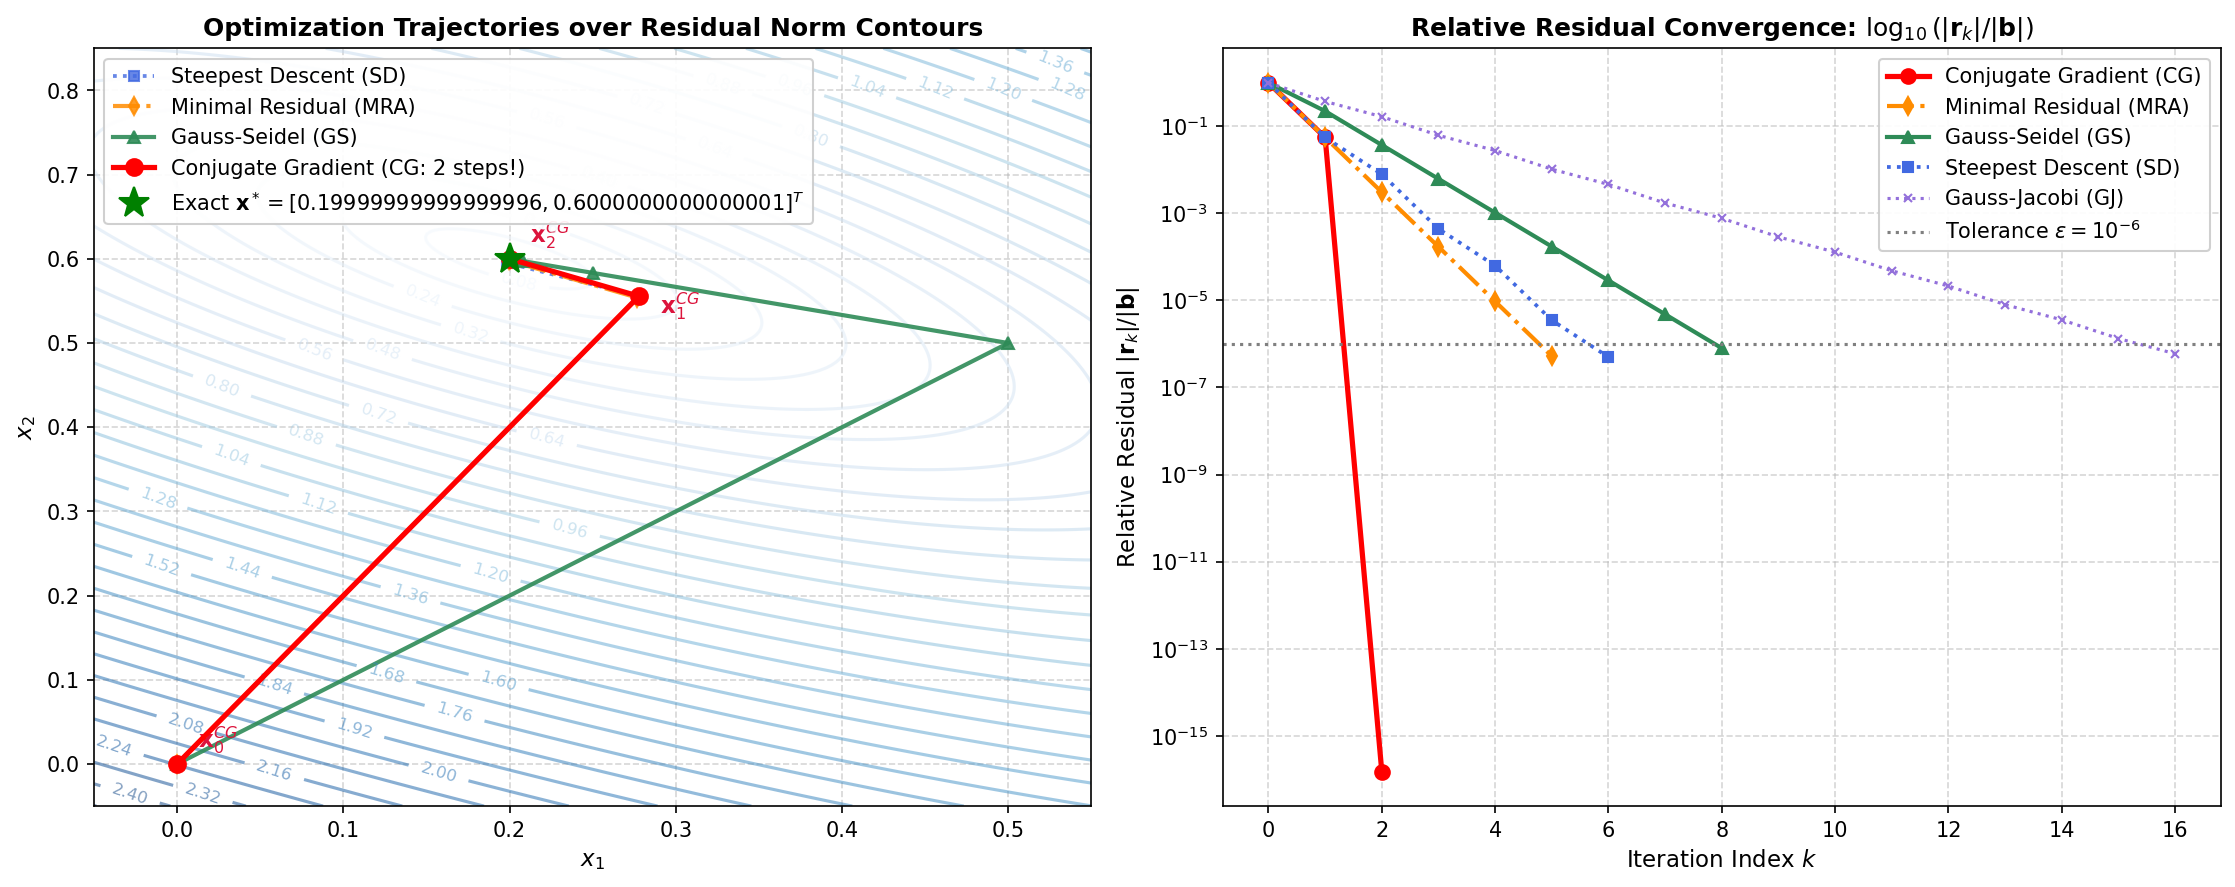

In [5]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), dpi=120)

# --- Plot 1: 2D State-Space Trajectory Comparison ---
x1_vals = np.linspace(-0.05, 0.55, 250)
x2_vals = np.linspace(-0.05, 0.85, 250)
X1, X2 = np.meshgrid(x1_vals, x2_vals)

R_norm = np.zeros_like(X1)
for i in range(X1.shape[0]):
    for j in range(X1.shape[1]):
        pt = np.array([X1[i, j], X2[i, j]])
        R_norm[i, j] = np.linalg.norm(b - A @ pt)

# Contour levels of residual norm
contours = ax1.contour(X1, X2, R_norm, levels=30, cmap='Blues', alpha=0.5)
ax1.clabel(contours, inline=True, fontsize=8, fmt='%.2f')

# Trajectory points
cg_pts  = np.array(hist_cg['x'])
mra_pts = np.array(hist_mra['x'])
sd_pts  = np.array(hist_sd['x'])
gs_pts  = np.array(hist_gs['x'])

ax1.plot(sd_pts[:8, 0], sd_pts[:8, 1], 's:', color='royalblue', linewidth=1.8, markersize=5, label='Steepest Descent (SD)', alpha=0.8)
ax1.plot(mra_pts[:6, 0], mra_pts[:6, 1], 'd-.', color='darkorange', linewidth=2, markersize=6, label='Minimal Residual (MRA)', alpha=0.85)
ax1.plot(gs_pts[:6, 0], gs_pts[:6, 1], '^-', color='seagreen', linewidth=2, markersize=6, label='Gauss-Seidel (GS)', alpha=0.9)
ax1.plot(cg_pts[:, 0], cg_pts[:, 1], 'ro-', linewidth=2.5, markersize=8, label='Conjugate Gradient (CG: 2 steps!)', zorder=6)

for idx, pt in enumerate(cg_pts):
    ax1.annotate(f"$\mathbf{{x}}_{idx}^{{CG}}$", (pt[0], pt[1]), textcoords="offset points", 
                 xytext=(10, -8 if idx==1 else 8), fontsize=11, fontweight='bold', color='crimson')

ax1.plot(x_star[0], x_star[1], 'g*', markersize=15, label=f'Exact $\mathbf{{x}}^* = [{x_star[0]}, {x_star[1]}]^T$', zorder=7)

ax1.set_title('Optimization Trajectories over Residual Norm Contours', fontsize=12, fontweight='bold')
ax1.set_xlabel('$x_1$', fontsize=11)
ax1.set_ylabel('$x_2$', fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='upper left', framealpha=0.92)

# --- Plot 2: Convergence Rates ---
ax2.semilogy(hist_cg['k'], hist_cg['rel_res'], 'ro-', linewidth=2.5, markersize=7, label='Conjugate Gradient (CG)')
ax2.semilogy(hist_mra['k'], hist_mra['rel_res'], 'd-.', color='darkorange', linewidth=2, markersize=6, label='Minimal Residual (MRA)')
ax2.semilogy(hist_gs['k'], hist_gs['rel_res'], '^-', color='seagreen', linewidth=2, markersize=6, label='Gauss-Seidel (GS)')
ax2.semilogy(hist_sd['k'], hist_sd['rel_res'], 's:', color='royalblue', linewidth=1.8, markersize=5, label='Steepest Descent (SD)')
ax2.semilogy(hist_gj['k'], hist_gj['rel_res'], 'x:', color='mediumpurple', linewidth=1.5, markersize=4, label='Gauss-Jacobi (GJ)')

ax2.axhline(1e-6, color='gray', linestyle=':', label='Tolerance $\epsilon = 10^{-6}$')
ax2.set_title('Relative Residual Convergence: $\log_{10}(\|\mathbf{r}_k\| / \|\mathbf{b}\|)$', fontsize=12, fontweight='bold')
ax2.set_xlabel('Iteration Index $k$', fontsize=11)
ax2.set_ylabel('Relative Residual $\|\mathbf{r}_k\| / \|\mathbf{b}\|$', fontsize=11)
ax2.grid(True, which='both', linestyle='--', alpha=0.5)
ax2.legend(loc='upper right', framealpha=0.92)

plt.tight_layout()
plt.show()


---
## Summary & Master Lecture Alignment

### Comparison of All Four Iterative Solvers
| Feature | Steepest Descent (Slide 25) | Minimal Residual (Slide 27) | Conjugate Gradients (Slide 29) | Gauss-Seidel / Jacobi (Slide 33) |
| :--- | :--- | :--- | :--- | :--- |
| **Objective** | Energy functional $\phi(\mathbf{x})$ | Residual 2-norm $\|\mathbf{r}_{k+1}\|^2$ | Error along mutually $A$-orthogonal directions | Matrix splitting $A = (D-L)-U$ into easy solve |
| **Search Direction** | $\mathbf{p}_k = \mathbf{r}_k$ (Local gradient) | $\mathbf{p}_k = \mathbf{r}_k$ (Local gradient) | $\mathbf{p}_k = \mathbf{r}_k + \beta_k \mathbf{p}_{k-1}$ ($A$-orthogonal) | Coordinate unit axes (relaxation) |
| **Step Scaling** | $d_k = \frac{\mathbf{r}_k^T \mathbf{r}_k}{\mathbf{r}_k^T A \mathbf{r}_k}$ | $d_k = \frac{\mathbf{r}_k^T A \mathbf{r}_k}{(A \mathbf{r}_k)^T (A \mathbf{r}_k)}$ | $\alpha_k = \frac{\mathbf{r}_k^T \mathbf{r}_k}{\mathbf{p}_k^T A \mathbf{p}_k}, \; \beta_k = \frac{\mathbf{r}_{k+1}^T \mathbf{r}_{k+1}}{\mathbf{r}_k^T \mathbf{r}_k}$ | Diagonal scalar division $\frac{1}{A_{ii}}$ |
| **Memory Registers** | $\mathbf{x}, \mathbf{r}$ ($O(N)$ storage) | $\mathbf{x}, \mathbf{r}$ ($O(N)$ storage) | $\mathbf{x}, \mathbf{r}, \mathbf{p}$ ($O(N)$ storage) | $\mathbf{x}$ in-place ($O(N)$ storage) |
| **Cost per Step** | 1 SpMV ($A \mathbf{r}_k$) | 1 SpMV ($A \mathbf{r}_k$) | 1 SpMV ($A \mathbf{p}_k$) | 1 Forward pass ($O(\text{NNZ})$) |
| **Matrix Support** | SPD matrices | Symmetric indefinite / SPD | SPD (preconditioned for stiff systems) | Strictly diagonally dominant or SPD |
| **Steps on $2 \times 2$** | 8 iterations | 6 iterations | **2 iterations (Exact mathematically!)** | 8 iterations (GS), 16 iterations (GJ) |

### Key Course Takeaways
1. **Why Conjugate Gradients Wins**: By forcing search directions to be $A$-orthogonal ($\mathbf{p}_0^T A \mathbf{p}_1 = 0$), CG never undoes previous work. For an $N \times N$ SPD matrix, it converges to the exact analytical solution in at most $N$ iterations (exactly 2 steps here).
2. **Why Steepest Descent Zig-Zags**: Consecutive directions are orthogonal in Euclidean space ($\mathbf{r}_{k+1}^T \mathbf{r}_k = 0$), forcing the trajectory into inefficient $90^\circ$ bounces down the energy valley.
3. **Gauss-Seidel Acceleration**: Re-using the updated $x_1^{(k+1)}$ immediately to compute $x_2^{(k+1)}$ squares the spectral radius ($\rho(T_{GS}) = \rho(T_J)^2 = 1/6$), halving the number of iterations compared to Jacobi.
4. **Zero Fill-in**: None of these algorithms compute matrix inverses or row reductions that destroy sparsity. They scale directly to millions of unknowns in finite-element and circuit simulations.